# 제9장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch09


## 9.11 K-Means와 DBSCAN의 비선형 군집 비교

중심까지의 거리와 밀도 연결이라는 서로 다른 군집 정의를 비교한다.

-1은 DBSCAN 잡음이다. ARI는 알려진 합성 정답을 사후 비교할 때만 사용하며 학습에는 넣지 않는다. 실루엣은 잡음 제외 표본으로 계산했다.

주의: 실루엣이 더 높다고 모든 형태에서 더 좋은 군집은 아니다. 비선형 구조와 업무 해석도 함께 검토한다.

In [2]:
%run sec_11_clustering_compare.py

{
  "KMeans": {
    "ARI": 0.4789688417784687,
    "noise_n": 0,
    "silhouette_without_noise": 0.4794676118145756
  },
  "DBSCAN": {
    "ARI": 0.016442244736271424,
    "noise_n": 15,
    "silhouette_without_noise": 0.17507986910405698
  }
}


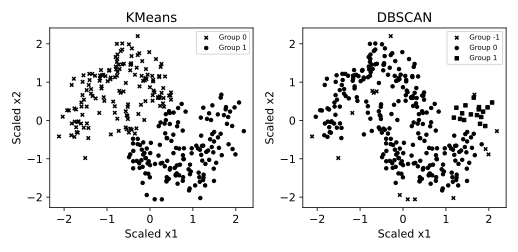

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/clustering_compare.svg"))

### 확인 과제

eps를 0.15와 0.5로 바꾸고 군집 수·잡음 수와 지표가 함께 어떻게 바뀌는지 기록한다.

## 9.12 PCA 설명 분산과 재구성 오차

차원 축소의 정보 보존을 훈련 설명 분산과 미관측 재구성 오차로 구분한다.

왼쪽은 훈련 분산의 누적 비율이다. 오른쪽 오차는 표준화된 입력 공간이며 원 단위 오차가 아니다.

주의: PCA는 정답을 보존하도록 최적화하지 않는다. 분산 보존이 분류 정확도나 군집 의미 보존을 보장하지 않는다.

In [4]:
%run sec_12_pca_reconstruction.py

{
  "train_n": 124,
  "test_n": 54,
  "variance_first2": 0.5496008722014621,
  "reconstruction": [
    {
      "components": 1,
      "scaled_test_mse": 0.6095364010651653
    },
    {
      "components": 2,
      "scaled_test_mse": 0.40088476657451155
    },
    {
      "components": 3,
      "scaled_test_mse": 0.3120173677869732
    },
    {
      "components": 5,
      "scaled_test_mse": 0.2209629414664772
    },
    {
      "components": 8,
      "scaled_test_mse": 0.08390779160474185
    },
    {
      "components": 13,
      "scaled_test_mse": 1.4499782735682569e-30
    }
  ]
}


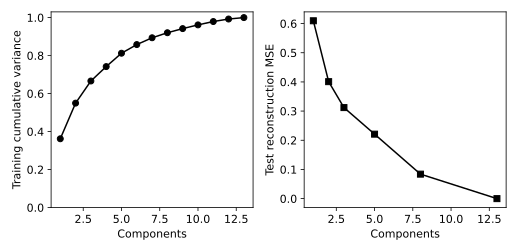

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/pca_reconstruction.svg"))

### 확인 과제

2차원 그림이 전체 정보를 얼마나 유지하는지 분산 비율로 설명하고 13차원 복원 오차가 수치적으로 0에 가까운지 확인한다.